# 모의고사 19회 | 설문 척도·국가별 추이·교호작용 회귀 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys

FOLDER = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(FOLDER.parent / "공통"))
from researched_core import ResearchContext

ctx = ResearchContext(FOLDER)

## 1. 설문 방향·신뢰도·차원 요약

**상황을 이해하기**

설문팀은 부정 문항의 방향을 맞추고 척도의 일관성과 집단 차이를 탐색한다.

**관측 단위와 판단 목적**

한 행은 독립 응답자이며 두 집단의 처치는 관측되지 않았다. 신뢰도·차원·집단 차이가 서로 다른 질문임을 설명한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 응답 식별자 |
| `group` | 관측 집단 A/B; 무작위 배정 아님 |
| `q1` | 서비스 편의 긍정 문항(1~5) |
| `q2` | 서비스 불편 부정 문항; 역변환 |
| `q3` | 이용 만족 긍정 문항(1~5) |
| `q4` | 이용 불만 부정 문항; 역변환 |

**고정 분석 조건**

독립 응답자180명, group A/B, 1~5 q1~q4. q2/q4는 역문항으로6-x 변환한다. 결측 문항이 있는 응답자는 본 과제의 완전 관측 분석에서 제외하고 그 수를 보고한다. 공분산 alpha와 표준화 alpha는 다른 식이다. 방향을 맞춘 문항4개에 표준화 PCA 2축을 적합한다. 집단별 완전 관측 평균 점수의 양측 Welch t 검정(alpha0.05)을 수행한다. PCA와 Welch는 후기에서 확정되지 않은 응용 확장이다.

### 1-1

**문제 (10점)**

1~5 척도 범위·결측을 확인하고 역문항 q2·q4를6-x로 변환하시오. id는 제외하고 집단별 평균·표준편차·왜도·첨도를 제시하시오.

**풀이 근거와 읽는 순서**

역문항은 방향을 맞추기 위한 변환이다.

평가 결과를 보고 반전 문항을 고르지 않으며 집단은 무작위 처치가 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [2]:
ctx.run("1-1", "survey_1")

complete_rows: 172
excluded_rows: 8


,q1_mean,q1_std,q1_skew,q1_kurtosis,q2_mean,q2_std,q2_skew,q2_kurtosis,q3_mean,q3_std,q3_skew,q3_kurtosis,q4_mean,q4_std,q4_skew,q4_kurtosis
A,2.934066,0.840664,-0.217858,-0.264796,3.000000,0.942809,1.444838e-16,-0.457010,2.923077,0.653720,0.321960,0.283534,2.956044,0.697807,0.059740,-0.908321
B,3.283951,0.911518,-0.194211,-0.669285,3.345679,0.910501,-2.398049e-01,-0.080598,3.148148,0.672888,-0.183502,-0.764571,3.246914,0.783117,0.171824,0.516497


conclusion: 결측 응답8명을 제외하고 q2/q4 방향을 맞췄다. 집단은 관측 범주이며 처치 효과를 뜻하지 않는다.


### 1-2

**문제 (10점)**

역변환 전후의 공분산 기반 Cronbach alpha와 평균 문항 간 상관 기반 표준화 alpha를 구하시오. 공식·문항 수·분모를 표시하고 신뢰도와 타당도·단일차원의 차이를 설명하시오.

**풀이 근거와 읽는 순서**

alpha=k/(k-1)×(1-문항분산합/총점분산), 표준화alpha=k rbar/(1+(k-1)rbar)다.

값이 높다고 단일차원이나 인과가 성립하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [3]:
ctx.run("1-2", "survey_2")

,metric,value
0,items,4.000000
1,alpha,-1.842382
2,standardized_alpha,-1.741070
3,mean_interitem_correlation,-0.188770
4,total_score_variance,1.129743


,metric,value
0,items,4.000000
1,alpha,0.733432
2,standardized_alpha,0.735979
3,mean_interitem_correlation,0.410688
4,total_score_variance,5.980552


conclusion: 방향 보정 뒤 공분산 alpha 0.7334, 표준화 alpha 0.7360. 두 식은 척도의 일관성 지표이며 단일차원·타당도 증명이 아니다.


### 1-3

**문제 (10점)**

방향을 맞춘 문항을 표준화한 PCA를 수행하고 축별 설명분산·적재 방향·재구성 오차를 보고하시오. PCA를 공통요인분석으로 부르지 말고 2축 그림을 제시하시오.

**풀이 근거와 읽는 순서**

PCA는 관측 변수의 총분산을 요약한다.

상관 구조가 같아도 신뢰도 수치만으로 차원 수를 결정하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

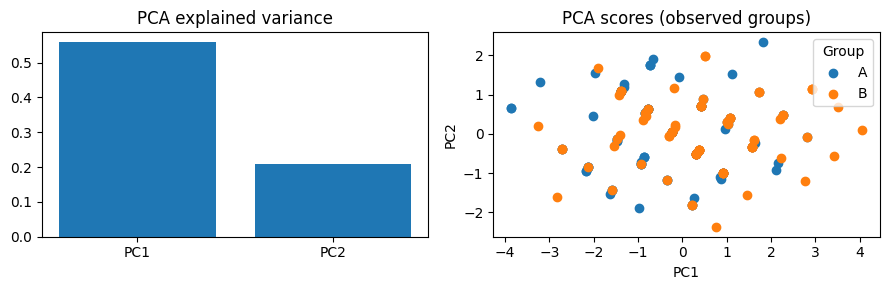

explained_variance_ratio: [0.5589531396556874, 0.2089169392919503]
components: [[0.5359383334035945, 0.50681783558599, 0.4695396564547358, 0.485219842274487], [-0.411730200974491, -0.5398453192104453, 0.5496536129229787, 0.4867506330070793]]
reconstruction_error: 0.232129921052362
conclusion: PCA2축은 총분산 0.768를 설명한다. 부호는 임의이며 PCA를 공통요인분석으로 부르지 않는다.


In [4]:
ctx.run("1-3", "survey_3")

### 1-4

**문제 (10점)**

완전 관측 응답자의 평균 점수를 집단 간 Welch t 검정으로 비교하시오. H0/H1·통계량·자유도·p값·95% 차이 CI·기각 여부·효과와 표본 한계를 설명하시오.

**풀이 근거와 읽는 순서**

완전 관측만 사용한 두 독립 표본 비교다.

다중 탐색 미보정과 설문 표본의 비대표성을 명시하며 집단 효과의 인과로 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [5]:
ctx.run("1-4", "survey_4")

test_type: Welch's T-test (Unequal Variance)
statistic: -3.3190906409633483
p_value: 0.0011146257660294959
reject_h0: True
alpha: 0.05
null_hypothesis: 평균 또는 평균차가 지정 귀무값과 같다
alternative: two-sided
method_used: welch-t


,metric,value
0,null_value,0.000000
1,estimate,-0.302876
2,sample_mean1,2.953297
3,sample_mean2,3.256173
4,sample_std1,0.566314
5,sample_std2,0.623718


warnings: []
mean_difference: -0.3028761362094694
standard_error: 0.09125274630088476
df: 162.64033531545616
confidence_interval: [-0.48306903598896545, -0.12268323642997336]
n_effective: 172
group_sizes: [91, 81]
conclusion: A−B 평균 점수 차이의 양측 Welch 검정 p=0.001115. 관측 표본의 비교이며 인과·모집단 대표성을 주장하지 않는다.


## 2. 가상 국가 누적 자료와 예측

**상황을 이해하기**

가상 누적 신고 자료를 차분하고 인구 규모를 고려한 비교표를 만든다.

**관측 단위와 판단 목적**

한 행은 국가·날짜별 합계이며 개별 환자가 아니다. 정정치·분모·단위와 임의 위험점수의 한계를 구분한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `country` | 실제 국가와 무관한 A~D |
| `date` | 등간격 일자 |
| `population` | 가상 인구; 분모 |
| `cases` | 수정 포함 누적 확진 건수 |
| `deaths` | 누적 사망 건수 |

**고정 분석 조건**

가상 국가 A~D 각70일. population은 국가 내 고정. 첫날 이전 누적0이며 음수 일별 정정이 한 건 있다. 누적 차분을 보존한다. 마지막날 위험점수=확진/인구×10000+사망/인구×100000이다. 이는 임의 합성 학습 점수다. 국가 A는 마지막7일만 최종평가하고 사전 ARIMA(1,0,0), trend c, 수렴 maxiter200을 사용한다. 기준은 직전7일 평균 고정 예측이다.

### 2-1

**문제 (8점)**

국가·날짜 key 중복과 누적수치·인구를 검증하고 국가별 누적 추이를 ax에 표시하시오. 가상 국가 자료이며 실제 방역 의사결정용이 아님을 명시하시오.

**풀이 근거와 읽는 순서**

국가별 동일 인구를 사용한다.

국가를 개별 환자로 보거나 누적수치를 일일 발생으로 취급하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

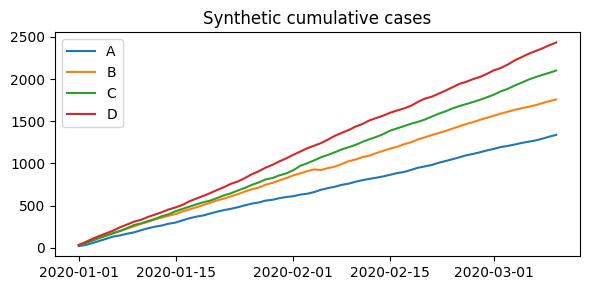

countries: 4
duplicate_keys: 0
conclusion: 가상 국가별 누적 신고 자료다. 실제 개인 위험이나 방역 정책으로 일반화하지 않는다.


In [6]:
ctx.run("2-1", "risk_1")

### 2-2

**문제 (7점)**

국가별 정렬 후 누적 확진·사망을 차분해 일별 값을 구하시오. 첫날 기저값0과 음수 정정치를 보존하고 그 위치를 제시하시오.

**풀이 근거와 읽는 순서**

음수 차분은 자료 정정의 표시다.

0으로 몰래 자르면 누적 합과 맞지 않으며 결측 대치와도 다르다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [7]:
ctx.run("2-2", "risk_2")

negative_corrections: 1


,country,date,daily_cases
105,B,2020-02-05T00:00:00,-8.0


conclusion: 음수 정정1건을0으로 자르지 않고 보존했다. 국가별 일별 합은 마지막 누적과 같다.


### 2-3

**문제 (8점)**

마지막 날의 누적확진/인구×10000과 누적사망/인구×100000을 각각 구하고 두 지표 합을 학습용 위험점수로 정의해 순위표·그림을 제시하시오.

**풀이 근거와 읽는 순서**

서로 다른 스케일 합은 지문에서 정한 임의 학습 점수다.

공중보건 표준 지수나 실제 개인 감염 확률로 표시하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

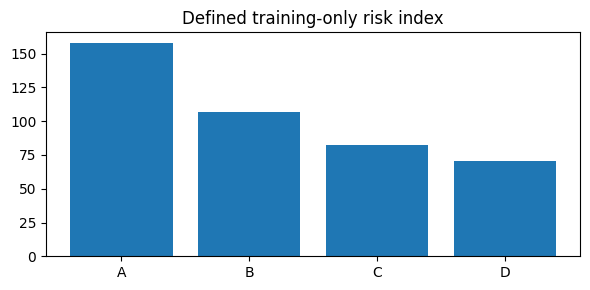

,country,case_rate_10000,death_rate_100000,score
69,A,133.900000,24.000000,157.900000
139,B,87.950000,18.500000,106.450000
209,C,70.066667,12.666667,82.733333
279,D,60.850000,9.750000,70.600000


conclusion: 최상위 가상 국가 A. 이는 지문에서 정의한 두 스케일 합이며 공인 보건지수나 감염 확률이 아니다.


In [8]:
ctx.run("2-3", "risk_3")

### 2-4

**문제 (7점)**

가상 국가 A의 일별 확진 마지막7일을 봉인하고 ARIMA(1,0,0) 및 직전7일 평균 기준을 같은 날짜에서 비교하시오. RMSE·MAE와 음수 예측·정정 자료의 한계를 제시하시오.

**풀이 근거와 읽는 순서**

국가별 시계열을 섞지 않고 과거만 적합한다.

연속 ARIMA는 정수·비음수 제약을 자동 보장하지 않으며 결과를 임의 자르지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [9]:
ctx.run("2-4", "risk_4")

train_end: 62
test_start: 63


,metric,value
0,rmse,3.359230
1,mae,2.884665
2,r2,-0.020179


,metric,value
0,rmse,3.374575
1,mae,2.897959
2,r2,-0.029520


baseline_predictions: [19.285714285714285, 19.285714285714285, 19.285714285714285, 19.285714285714285, 19.285714285714285, 19.285714285714285, 19.285714285714285]
conclusion: ARIMA RMSE 3.3592, 과거7일 평균 3.3746. 연속 모형은 건수의 정수·비음수 제약을 자동 보장하지 않는다.


## 3. 주택 교호작용과 예측

**상황을 이해하기**

관측의 조건과 결과 관계를 설명하고 새 관측의 결과를 예측한다.

**관측 단위와 판단 목적**

한 행은 서로 독립인 관측이다. x1=면적 편차지수, x2=노후도 편차지수, x3=접근 점수, target=주택가격(천만원). 추론의 조건과 예측 성능을 구분해 보고한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 독립 관측 식별자; 입력 제외 |
| `x1` | 면적 편차지수 |
| `x2` | 노후도 편차지수 |
| `x3` | 접근 점수 |
| `group` | 관측 집단 범주 A/B; 처치 아님 |
| `target` | 주택가격(천만원) |

**고정 분석 조건**

x1=면적 편차지수, x2=노후도 편차지수, x3=접근 점수, target=주택가격(천만원). 240행. x1에 결측이 있다. id를 제외하고 중앙값 대치 후 수치형은 학습 평균/표준편차(ddof0)로 표준화하고 집단은 one-hot(drop first) 처리한 뒤 OLS를 적합한다. x1,x2,x3의 단순/전체모형 비교는 같은 학습 행이다. 설명용 전체모형은 표준화한 x1×x2 교호작용을 추가한다. random_state=20281019로 학습70%/평가30%를 나누고 학습3-fold shuffled CV를 사용한다. 다항식 차수2, RF60나무 깊이3/5는 사전 후보다.

### 3-1

**문제 (8점)**

관측 단위·입력·반응·누출 위험과 결측을 정리하고 지정한 학습/평가 원행을 기록하시오. 학습 입력의 분포와 변수 관계를 ax 두 개에 제시하시오.

**풀이 근거와 읽는 순서**

식별자·사후 반응은 제외하고 대치는 학습 자료에서만 추정한다.

평가 설계를 먼저 고정한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

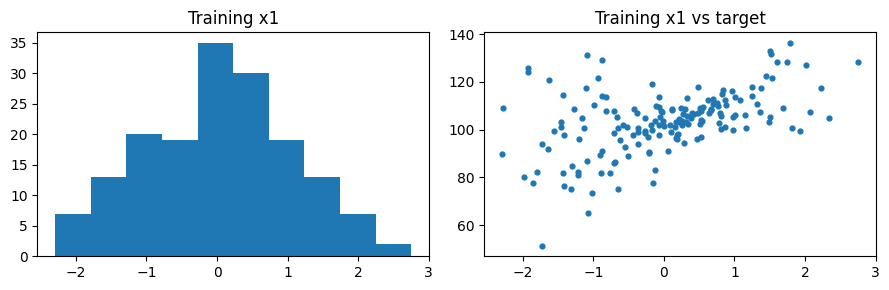

n: 240


,metric,value
0,x1,3
1,x2,0
2,x3,0
3,group,0


conclusion: 학습 168행·봉인 평가 72행. 실제값으로 만든 파생변수는 사용하지 않는다.


In [10]:
ctx.run("3-1", "reg_1")

### 3-2

**문제 (7점)**

학습 자료에 지정 OLS를 적합하고 계수 t 검정·전체 F 검정·R²·수정 R²·AIC·BIC를 보고하시오. 단순모형과 전체모형의 비교에서 같은 행과 반응을 유지하시오.

**풀이 근거와 읽는 순서**

t는 조건부 계수, F는 전체 설명항의 검정이다.

학습 R²와 예측 성능을 구분하며 같은 반응·행에서만 정보량을 비교한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [11]:
ctx.run("3-2", "reg_2")

coefficient_scale: 수치형은 학습 표준편차1단위, 범주는 B−A. 교호작용은 표준화 좌표의 곱.


,term,coefficient,standard_error,t_statistic,p_value,ci_lower,ci_upper,reject_h0
0,Intercept,100.015299,0.361363,276.772257,1.173578e-218,99.301710,100.728889,True
1,numeric__x1,8.879579,0.267947,33.139277,4.579247e-74,8.350459,9.408699,True
2,numeric__x2,-5.049539,0.264557,-19.086776,2.665053e-43,-5.571963,-4.527114,True
3,numeric__x3,3.625237,0.263308,13.768035,4.712887e-29,3.105278,4.145196,True
4,category__group_B,4.052362,0.526031,7.703658,1.245242e-12,3.013601,5.091124,True
5,x1:x2,9.134828,0.258003,35.405933,3.694768e-78,8.625345,9.644310,True


,metric,value
0,r2,0.938276
1,adjusted_r2,0.936371
2,r2_kind,centered
3,f_statistic,492.515912
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,5.0
7,df_resid,162.0
8,n_samples,168
9,aic,891.783075


,metric,value
0,r2,0.225873
1,adjusted_r2,0.22121
2,r2_kind,centered
3,f_statistic,48.43509
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,1.0
7,df_resid,166.0
8,n_samples,168
9,aic,1308.665216


,test,statistic,p_value,reject_h0,df_num,df_den
0,nested-model F,467.439497,8.152148e-88,True,4.0,162.0


conclusion: 학습 R² 0.9383는 봉인 평가 성능이 아니다. 계수 t·F는 사전 OLS 사양과 추론 가정에 조건부다.


### 3-3

**문제 (8점)**

RESET·잔차 정규성·Breusch-Pagan·VIF·Cook을 계산하고 Q-Q·잔차/적합값을 subplots로 제시하시오. 명시하지 않은 관측 제거를 수행하지 말고 진단별 한계를 설명하시오.

**풀이 근거와 읽는 순서**

정규성은 y가 아니라 잔차를 대상으로 한다.

VIF는 변수의 공선성, Cook은 관측 영향력이다.

비기각을 가정 증명으로 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

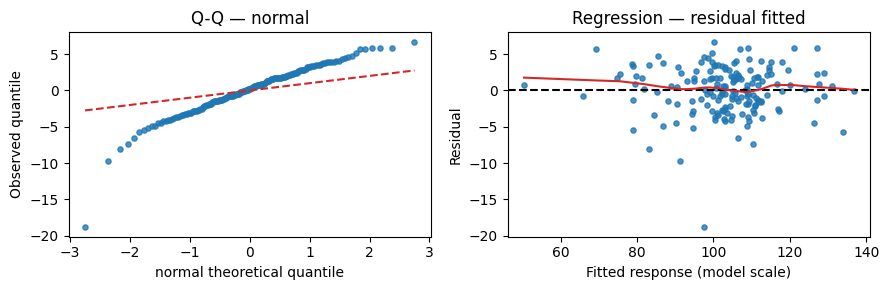

,test,statistic,p_value,reject_h0,df_num,df_den
0,jarque_bera,230.562731,8.588930e-51,True,None,None


,test,statistic,p_value,reject_h0,df_num,df_den
0,RESET F,0.487038,0.615352,False,2.0,160.0


,test,statistic,p_value,reject_h0,df_num,df_den
0,breusch_pagan LM,4.104612,0.534455,False,None,None
1,breusch_pagan F,0.811429,0.543089,False,None,None


,feature,vif,tolerance,flag
0,numeric__x1,1.056265,0.946732,False
1,numeric__x2,1.029704,0.971153,False
2,numeric__x3,1.020007,0.980385,False
3,category__group_B,1.014134,0.986063,False
4,x1:x2,1.020566,0.979848,False


,position,row_label,residual,studentized_internal,studentized_external,leverage,cooks_distance,dffits,outlier_p,adjusted_outlier_p,cook_flag,leverage_flag,studentized_flag,outlier_reject,original_position
49,49,49,-18.841782,-5.640477,-6.272610,0.022814,0.123796,-0.958432,3.141939e-09,5.278458e-07,True,False,True,True,223
99,99,99,-5.693894,-1.767240,-1.779009,0.090940,0.052072,-0.562677,7.712516e-02,1.000000e+00,True,True,False,False,92
2,2,2,6.714437,2.049367,2.070041,0.059963,0.044651,0.522817,4.004552e-02,1.000000e+00,True,False,False,False,109
144,144,144,-9.698148,-2.914649,-2.984957,0.030450,0.044467,-0.528988,3.278900e-03,5.508552e-01,True,False,False,False,35
82,82,82,5.645988,1.742274,1.753393,0.080372,0.044216,0.518353,8.143769e-02,1.000000e+00,True,True,False,False,83


removed_rows: 0
conclusion: 본 풀이에서는 영향 관측을 삭제하지 않는다. 진단은 사양 점검이며 비기각을 가정의 증명으로 읽지 않는다.


In [12]:
ctx.run("3-3", "reg_3")

### 3-4

**문제 (7점)**

동일 학습 CV에서 기준 선형모형·다항식·랜덤포레스트를 RMSE로 비교해 하나를 선택하시오. 봉인한 같은 평가 행에서 원단위 RMSE·MAE·R²와 관측-예측 그림을 제시하고 기준 대비 차이를 해석하시오.

**풀이 근거와 읽는 순서**

전처리를 CV 안에서 적합한다.

설명용 OLS 진단과 선택한 예측모형의 적용 조건을 구분하고 최종평가로 다시 고르지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

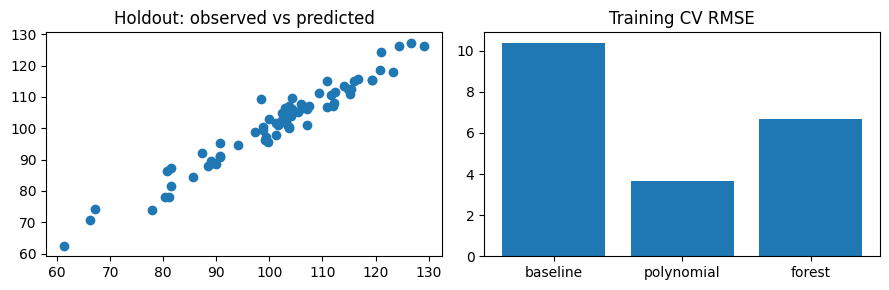

,candidate,cv_rmse,parameters
0,baseline,10.374069,{}
1,polynomial,3.657878,{}
2,forest,6.669243,{'model__max_depth': 5}


selected: polynomial


,metric,value
0,rmse,3.186857
1,mae,2.447851
2,r2,0.948119


,metric,value
0,rmse,9.526220
1,mae,7.264978
2,r2,0.536418


delta_r2: 0.41170044007498907
baseline_predictions: [105.02566830629513, 99.02858598050754, 103.60419869436706, 103.24352301660264, 102.48645700993082, 101.45015194655876, 102.72352049224158, 106.26896533617982, 97.91928672118941, 124.1553720499029, 96.07964418979476, 98.46881805526057, 111.65248860654727, 115.13321370453666, 105.90734005803164, 98.09963254933385, 86.68711331821534, 114.66752221288813, 107.6876096251072, 99.45196216252981, 86.35523495961925, 107.30487617164532, 115.13318526116151, 110.97471868227396, 94.21929470272879, 84.4842484313159, 105.48449320032567, 119.58419576043208, 121.73017769741244, 99.81011428202572, 110.53660050013642, 108.82325281833234, 108.29566429680365, 102.0155318377309, 109.22735602651112, 101.63726348079288, 113.27513060720565, 106.45492260342566, 100.15565385504696, 120.58164679962015, 90.60979056181631, 91.55880697762902, 95.71975129212487, 101.28322068886226, 111.44640726677977, 101.59799241219137, 92.43187304409645, 108.11588320530589, 98.295

In [13]:
ctx.run("3-4", "reg_4")